# Uniform-posterior experiment for Theorem 3.1 and Corollary 3.2

This notebook runs the uniform-posterior example from the paper. **Run All** regenerates the data, tables, and figures using fixed random seeds. The Gibbs posterior is not included here.


## 1. Packages

Import the packages used in the experiment.


In [1]:
from dataclasses import asdict, dataclass
from functools import lru_cache
from pathlib import Path
import json
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from numpy.polynomial.legendre import leggauss
from scipy.optimize import brentq, minimize, minimize_scalar
from scipy.special import logsumexp, ndtri
from scipy.stats import qmc

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 180)
pd.set_option("display.float_format", lambda value: f"{value:.9g}")


## 2. Settings

We use $N\in\{4,500,1000,2000,4000,8000,16000,32000,64000\}$. The main experiment has 40 independent trials, with another 400 trials at $N_g=4$. The seed is `20260725`.

For bounded data, the input and output noise half-widths are 0.05 and 0.005. For unbounded data, we use a Rademacher amplitude of 0.0125, Gaussian standard deviation of 0.0000625, and output noise scale of 0.25. The prior and posterior half-widths are 0.40 and 0.05.

We use 160 burn-in steps, 40 stationary history lags, $2^{15}$ Sobol points for absolute true error, 25 posterior quadrature nodes, and 3721 prior nodes. Impulse sums use 160 lags. For a 90% two-sided bound, each one-sided calculation uses $\delta=0.025$.


In [ ]:
@dataclass(frozen=True)
class Settings:

    seed: int = 20260725
    sample_sizes: tuple[int, ...] = (
        4,
        500,
        1000,
        2000,
        4000,
        8000,
        16000,
        32000,
        64000,
    )
    monte_carlo_trials: int = 40
    early_gap_trials: int = 400
    total_two_sided_failure_probability: float = 0.10

    # Bounded noise.
    bounded_input_half_width: float = 0.05
    bounded_output_half_width: float = 0.005

    # Unbounded noise.
    unbounded_rademacher_amplitude: float = 0.0125
    unbounded_gaussian_sigma: float = 0.0000625
    unbounded_output_scale_ratio: float = 0.25

    prior_half_width: float = 0.40
    posterior_half_width: float = 0.05

    burnin: int = 160
    stationary_history: int = 40
    qmc_power: int = 15
    posterior_quadrature_order: int = 5
    prior_quadrature_order: int = 61
    impulse_horizon: int = 160

    @property
    def theorem_delta(self) -> float:
        """Confidence value for each one-sided theorem bound."""

        return self.total_two_sided_failure_probability / 4.0


## 3. System and predictor

We use the innovation-form system

$$
\mathbf x_g(t+1)=A_g\mathbf x_g(t)+K_g\mathbf e_g(t),\qquad
\begin{bmatrix}\mathbf y(t)\\\mathbf u(t)\end{bmatrix}
=C_g\mathbf x_g(t)+\mathbf e_g(t),\quad
\mathbf e_g(t)=\begin{bmatrix}\mathbf v(t)\\\mathbf u(t)\end{bmatrix}.
$$

There are 3 states, 2 inputs, and 2 outputs. The matrices are

$$
A_g=\begin{bmatrix}0.25&0&0\\0&0.20&0\\0&0&0.125\end{bmatrix},\quad
K_g=\begin{bmatrix}0&0&0.02&0\\0&0&0&0.02\\0&0&0.70&0.63\end{bmatrix},\quad
C_g=\begin{bmatrix}0.70&0&0\\0&0.70&0\\0&0&0\\0&0&0\end{bmatrix}.
$$

The predictor starts at zero and uses $\widehat{\mathbf x}(t+1)=\widehat A_\theta\widehat{\mathbf x}(t)+B\mathbf u(t)$ and $\widehat{\mathbf y}_\theta(t\mid0)=C\widehat{\mathbf x}(t)$, where

$$
\widehat A_\theta=A_g+(\theta_1-1)D_1+(\theta_2-1)D_2,\quad
(D_1)_{13}=3.700,\quad(D_2)_{23}=3.404.
$$

Here $K_g=[0_{3\times2}\ B]$ and the first two rows of $C_g$ form $C$. At $\theta_{\rm true}=(1,1)$, $\widehat A_\theta=A_g$. Every $\widehat A_\theta$ is upper triangular with eigenvalues 0.25, 0.20, and 0.125, so it is stable over the whole prior.


In [ ]:
@dataclass(frozen=True)
class System:

    A_star: np.ndarray
    A_directions: np.ndarray
    B: np.ndarray
    C: np.ndarray

    @property
    def state_dim(self) -> int:
        return int(self.A_star.shape[0])

    @property
    def input_dim(self) -> int:
        return int(self.B.shape[1])

    @property
    def output_dim(self) -> int:
        return int(self.C.shape[0])

    @property
    def innovation_dim(self) -> int:
        return self.input_dim + self.output_dim

    def A_theta(self, theta: np.ndarray) -> np.ndarray:
        """Compute A_theta from the two parameter directions."""

        return self.A_star + np.einsum(
            "j,jab->ab", np.asarray(theta, dtype=float) - 1.0, self.A_directions
        )

def make_system() -> System:
    """Create the three-state example used in the paper."""

    directions = np.zeros((2, 3, 3))
    directions[0, 0, 2] = 3.700
    directions[1, 1, 2] = 3.404
    return System(
        A_star=np.diag([0.25, 0.20, 0.125]).astype(float),
        A_directions=directions,
        B=np.array(
            [
                [0.02, 0.00],
                [0.00, 0.02],
                [0.70, 0.63],
            ],
            dtype=float,
        ),
        C=np.array(
            [
                [0.70, 0.00, 0.00],
                [0.00, 0.70, 0.00],
            ],
            dtype=float,
        ),
    )


### Set up the example

Create `settings`, `system`, and the matrices used in the paper. We also check the dimensions, the true parameter, and the spectral radius at the four prior corners. Stability over the full prior follows from the triangular form of $\widehat A_\theta$.


In [4]:
settings = Settings()
system = make_system()
OUTPUT_DIR = Path.cwd() / "uniform_detailed_outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

A_g = system.A_star
D_1, D_2 = system.A_directions
B = system.B
C = system.C
K_g = np.hstack((np.zeros((system.state_dim, system.output_dim)), B))
C_g = np.vstack((C, np.zeros((system.input_dim, system.state_dim))))
theta_true = np.ones(2)

prior_corners = np.array(
    [[a, b] for a in (0.6, 1.4) for b in (0.6, 1.4)], dtype=float
)
prior_corner_radii = np.array(
    [max(abs(np.linalg.eigvals(system.A_theta(theta)))) for theta in prior_corners]
)

assert system.state_dim == 3 and system.input_dim == 2 and system.output_dim == 2
assert np.allclose(system.A_theta(theta_true), A_g)
assert np.allclose(prior_corner_radii, 0.25)

print("A_g =\n", A_g)
print("K_g =\n", K_g)
print("C_g =\n", C_g)
print("D_1 =\n", D_1)
print("D_2 =\n", D_2)
print("theta_true =", theta_true)
print("sample sizes =", settings.sample_sizes)
print("output directory =", OUTPUT_DIR)


A_g =
 [[0.25  0.    0.   ]
 [0.    0.2   0.   ]
 [0.    0.    0.125]]
K_g =
 [[0.   0.   0.02 0.  ]
 [0.   0.   0.   0.02]
 [0.   0.   0.7  0.63]]
C_g =
 [[0.7 0.  0. ]
 [0.  0.7 0. ]
 [0.  0.  0. ]
 [0.  0.  0. ]]
D_1 =
 [[0.  0.  3.7]
 [0.  0.  0. ]
 [0.  0.  0. ]]
D_2 =
 [[0.    0.    0.   ]
 [0.    0.    3.404]
 [0.    0.    0.   ]]
theta_true = [1. 1.]
sample sizes = (4, 500, 1000, 2000, 4000, 8000, 16000, 32000, 64000)
output directory = /content/uniform_detailed_outputs


## 4. Losses and noise sampler

We use absolute loss $\ell_A(\mathbf y,\widehat{\mathbf y})=\|\mathbf y-\widehat{\mathbf y}\|_2$ and quadratic loss $\ell_Q(\mathbf y,\widehat{\mathbf y})=\|\mathbf y-\widehat{\mathbf y}\|_2^2$.

For unbounded data, each noise coordinate is $X=aR+\sigma Z$, with a Rademacher sign $R\in\{-1,1\}$ and standard normal $Z$. The sampler uses the given random generator so results are reproducible.


In [5]:
def loss_from_residual(residual: np.ndarray, loss_name: str) -> np.ndarray:
    """Compute absolute or quadratic loss."""

    squared_norm = np.sum(residual * residual, axis=-1)
    if loss_name == "absolute":
        return np.sqrt(squared_norm)
    if loss_name == "quadratic":
        return squared_norm
    raise ValueError(f"Unknown loss: {loss_name}")

def sample_rademacher_gaussian(
    rng: np.random.Generator,
    shape: tuple[int, ...],
    amplitude: float,
    sigma: float,
) -> np.ndarray:
    """Draw Rademacher-Gaussian noise."""

    signs = 2.0 * rng.integers(0, 2, size=shape) - 1.0
    return amplitude * signs + sigma * rng.normal(size=shape)


## 5. Simulating data

`simulate_trajectory` generates the input $\mathbf u(t)$ and output noise $\mathbf v(t)$. In the bounded case, $u_i\sim U[-0.05,0.05]$ and $v_i\sim U[-0.005,0.005]$. In the unbounded case,

$$
u_i=0.0125R_{u,i}+0.0000625Z_{u,i},\qquad
v_i=0.25(0.0125R_{v,i}+0.0000625Z_{v,i}).
$$

The output is $\mathbf y(t)=C\mathbf x_g(t)+\mathbf v(t)$ and the state follows $\mathbf x_g(t+1)=A_g\mathbf x_g(t)+B\mathbf u(t)$. We discard the first 160 steps. Both returned arrays have shape `(n, 2)`. The predictor starts from zero at the beginning of each retained record.


In [6]:
def simulate_trajectory(
    regime: str,
    n: int,
    rng: np.random.Generator,
    settings: Settings,
    system: System,
) -> tuple[np.ndarray, np.ndarray]:
    """Simulate one input-output trajectory after burn-in."""

    total = settings.burnin + n
    if regime == "bounded":
        u = rng.uniform(
            -settings.bounded_input_half_width,
            settings.bounded_input_half_width,
            size=(total, system.input_dim),
        )
        output_noise = rng.uniform(
            -settings.bounded_output_half_width,
            settings.bounded_output_half_width,
            size=(total, system.output_dim),
        )
    elif regime == "unbounded":
        u = sample_rademacher_gaussian(
            rng,
            (total, system.input_dim),
            settings.unbounded_rademacher_amplitude,
            settings.unbounded_gaussian_sigma,
        )
        output_noise = sample_rademacher_gaussian(
            rng,
            (total, system.output_dim),
            settings.unbounded_rademacher_amplitude
            * settings.unbounded_output_scale_ratio,
            settings.unbounded_gaussian_sigma
            * settings.unbounded_output_scale_ratio,
        )
    else:
        raise ValueError(regime)

    state = np.zeros(system.state_dim)
    y = np.empty((n, system.output_dim))
    scored_index = 0
    for t in range(total):
        if t >= settings.burnin:
            y[scored_index] = system.C @ state + output_noise[t]
            scored_index += 1
        state = system.A_star @ state + system.B @ u[t]
    return y, u[settings.burnin :]


## 6. Predictor features

For this system, the predicted output is exactly linear in the parameters apart from a fixed term:

$$
\widehat{\mathbf y}_\theta(t\mid0)=\mathbf b(t)+F(t)\theta.
$$

`finite_affine_features` finds $\mathbf b(t)$ and $F(t)$ by running the predictor at $(0,0)$, $(1,0)$, and $(0,1)$. Their shapes are `(N, 2)` and `(N, 2, 2)`. We reuse these features when fitting the posterior center and evaluating losses.


In [7]:
def finite_affine_features(
    system: System, u: np.ndarray
) -> tuple[np.ndarray, np.ndarray]:
    """Compute the base output and parameter features."""

    probes = np.array([[0.0, 0.0], [1.0, 0.0], [0.0, 1.0]])
    transitions = np.stack([system.A_theta(theta) for theta in probes])
    states = np.zeros((3, system.state_dim))
    outputs = np.empty((len(u), 3, system.output_dim))
    for t, u_t in enumerate(u):
        outputs[t] = states @ system.C.T
        states = np.einsum("qab,qb->qa", transitions, states)
        states += system.B @ u_t
    base = outputs[:, 0, :]
    features = np.stack(
        [outputs[:, 1, :] - base, outputs[:, 2, :] - base], axis=-1
    )
    return base, features

def prediction(
    base: np.ndarray, features: np.ndarray, theta: np.ndarray
) -> np.ndarray:
    """Predict outputs using the affine features."""

    return base + np.einsum("toj,j->to", features, theta)


### Check the noise variances

For $X\sim U[-a,a]$, $\operatorname{Var}(X)=a^2/3$. Thus the bounded input and output variances are $0.05^2/3$ and $0.005^2/3$.

For unbounded inputs, $\operatorname{Var}(u_i)=0.0125^2+0.0000625^2$, and $\operatorname{Var}(v_i)=0.25^2\operatorname{Var}(u_i)$. These values are used for the quadratic true error.


In [8]:
bounded_input_variance = settings.bounded_input_half_width**2 / 3.0
bounded_output_variance = settings.bounded_output_half_width**2 / 3.0
unbounded_input_variance = (
    settings.unbounded_rademacher_amplitude**2
    + settings.unbounded_gaussian_sigma**2
)
unbounded_output_variance = (
    settings.unbounded_output_scale_ratio**2 * unbounded_input_variance
)

innovation_variances = pd.DataFrame(
    [
        {"case": "B", "coordinate": "u_i(t)", "variance": bounded_input_variance},
        {"case": "B", "coordinate": "v_i(t)", "variance": bounded_output_variance},
        {"case": "U", "coordinate": "u_i(t)", "variance": unbounded_input_variance},
        {"case": "U", "coordinate": "v_i(t)", "variance": unbounded_output_variance},
    ]
)
innovation_variances


,case,coordinate,variance
0,B,u_i(t),0.000833333333
1,B,v_i(t),8.33333333e-06
2,U,u_i(t),0.000156253906
3,U,v_i(t),9.76586914e-06


## 7. Uniform prior and posterior

The prior is $\pi=U([0.6,1.4]^2)$. After finding $\widehat\theta_N$, the posterior is uniform over the square of half-width 0.05 centered at $\widehat\theta_N$:

$$
\rho_D=U\left([\widehat\theta_{N,1}-0.05,\widehat\theta_{N,1}+0.05]\times[\widehat\theta_{N,2}-0.05,\widehat\theta_{N,2}+0.05]\right).
$$

Posterior averages use 25 weighted Gauss–Legendre nodes, not random posterior samples. Because the posterior lies inside the prior, the exact KL term is $\mathrm{KL}(\rho_D\Vert\pi)=2\ln(0.40/0.05)=2\ln8$.


In [9]:
def posterior_quadrature(
    center: np.ndarray, settings: Settings
) -> tuple[np.ndarray, np.ndarray]:
    """Return the posterior quadrature nodes and weights."""

    nodes, weights = leggauss(settings.posterior_quadrature_order)
    grid = np.stack(np.meshgrid(nodes, nodes, indexing="ij"), axis=-1)
    theta = center[None, :] + settings.posterior_half_width * grid.reshape(-1, 2)
    tensor_weights = np.outer(weights, weights).reshape(-1)
    return theta, tensor_weights / tensor_weights.sum()

def uniform_box_kl(settings: Settings) -> float:
    """Compute the exact KL between the two uniform boxes."""

    return 2.0 * math.log(
        settings.prior_half_width / settings.posterior_half_width
    )


## 8. Fitting the posterior center

For each data prefix, we minimize the empirical loss:

$$
\widehat\theta_N\in\operatorname*{arg\,min}_{\theta\in[0.65,1.35]^2}\widehat{\mathcal L}_N(\theta),\quad
\widehat{\mathcal L}_N(\theta)=\frac1N\sum_{t=0}^{N-1}\ell(\mathbf y(t),\widehat{\mathbf y}_\theta(t\mid0)).
$$

The center stays in $[0.65,1.35]^2$ so the entire posterior stays inside the prior. We start with least squares and use L-BFGS-B for the requested loss. Powell is a fallback if needed. The result is the posterior center, not a posterior sample.


In [10]:
def fit_posterior_center(
    y: np.ndarray,
    base: np.ndarray,
    features: np.ndarray,
    loss_name: str,
    settings: Settings,
) -> np.ndarray:
    """Fit the posterior center inside the allowed box."""

    lower = 1.0 - settings.prior_half_width + settings.posterior_half_width
    upper = 1.0 + settings.prior_half_width - settings.posterior_half_width
    design = features.reshape(-1, 2)
    target = (y - base).reshape(-1)
    initial, *_ = np.linalg.lstsq(design, target, rcond=None)
    initial = np.clip(initial, lower, upper)

    def objective_and_gradient(theta: np.ndarray) -> tuple[float, np.ndarray]:
        residual = y - prediction(base, features, theta)
        squared_norm = np.sum(residual * residual, axis=1)
        if loss_name == "absolute":
            denominator = np.sqrt(squared_norm)
            values = denominator
            denominator = np.maximum(denominator, 1.0e-14)
            scaled_residual = residual / denominator[:, None]
            gradient = (
                -np.einsum("toj,to->j", features, scaled_residual) / len(y)
            )
        elif loss_name == "quadratic":
            values = squared_norm
            gradient = (
                -2.0 * np.einsum("toj,to->j", features, residual) / len(y)
            )
        else:
            raise ValueError(loss_name)
        return float(np.mean(values)), gradient

    result = minimize(
        objective_and_gradient,
        initial,
        method="L-BFGS-B",
        jac=True,
        bounds=[(lower, upper), (lower, upper)],
        options={"maxiter": 200, "ftol": 1.0e-13, "gtol": 1.0e-10},
    )
    if result.success:
        return np.asarray(result.x, dtype=float)

    fallback = minimize(
        lambda theta: objective_and_gradient(theta)[0],
        initial,
        method="Powell",
        bounds=[(lower, upper), (lower, upper)],
        options={"maxiter": 500, "xtol": 1.0e-10, "ftol": 1.0e-12},
    )
    if not fallback.success:
        raise RuntimeError(f"Posterior-center fit failed: {fallback.message}")
    return np.asarray(fallback.x, dtype=float)


## 9. Posterior average of empirical loss

`empirical_posterior_risk` computes $\mathbb E_{\rho_D}\widehat{\mathcal L}_N$. For absolute loss, it uses the 25 posterior nodes. For quadratic loss, the affine predictor gives an exact expression:

$$
\mathbb E_{\rho_D}\widehat{\mathcal L}_N(\theta)
=\widehat{\mathcal L}_N(\widehat\theta_N)
+\frac{0.05^2}{3N}\sum_{t=0}^{N-1}\|F(t)\|_F^2.
$$

No posterior sampling is needed.


In [11]:
def empirical_posterior_risk(
    y: np.ndarray,
    base: np.ndarray,
    features: np.ndarray,
    center: np.ndarray,
    loss_name: str,
    settings: Settings,
) -> float:
    """Average the empirical loss over the posterior."""

    if loss_name == "quadratic":
        center_residual = y - prediction(base, features, center)
        center_loss = float(
            np.mean(np.sum(center_residual * center_residual, axis=1))
        )
        posterior_variance = settings.posterior_half_width**2 / 3.0
        feature_energy = float(
            np.mean(np.sum(features * features, axis=(1, 2)))
        )
        return center_loss + posterior_variance * feature_energy
    if loss_name != "absolute":
        raise ValueError(loss_name)

    theta_nodes, weights = posterior_quadrature(center, settings)
    total = 0.0
    for theta, weight in zip(theta_nodes, weights):
        residual = y - prediction(base, features, theta)
        total += weight * float(
            np.mean(loss_from_residual(residual, loss_name))
        )
    return float(total)


### Check posterior support and KL

For a square centered at $\theta_{\rm true}=(1,1)$, the nodes lie between 0.95 and 1.05, the weights sum to one, and $\mathrm{KL}=2\ln8$. The checks below verify these properties before we fit data-dependent centers.


In [12]:
posterior_nodes, posterior_weights = posterior_quadrature(theta_true, settings)
posterior_check = pd.DataFrame(
    [{
        "smallest node": posterior_nodes.min(),
        "largest node": posterior_nodes.max(),
        "number of nodes": len(posterior_nodes),
        "weight sum": posterior_weights.sum(),
        "KL(rho_D || pi)": uniform_box_kl(settings),
    }]
)
assert np.isclose(posterior_weights.sum(), 1.0)
assert np.isclose(uniform_box_kl(settings), 2.0 * np.log(8.0))
posterior_check


,smallest node,largest node,number of nodes,weight sum,KL(rho_D || pi)
0,0.954691008,1.04530899,25,1,4.15888308


## 10. Features for the true loss

The true loss $\mathcal L(\theta)$ is the stationary expected loss, rather than the loss on a finite training record. `affine_markov_features` builds the input-response coefficients $C\widehat A_\theta^kB$ using the same three parameter probes as above.

The result has shape `(history, output, input, parameter)`. We use it for the Sobol estimate of absolute loss and the second-moment formula for quadratic loss.


In [13]:
def affine_markov_features(
    system: System, history: int
) -> np.ndarray:
    """Compute affine features of the impulse responses."""

    probes = np.array([[0.0, 0.0], [1.0, 0.0], [0.0, 1.0]])
    transitions = np.stack([system.A_theta(theta) for theta in probes])
    powers = np.repeat(np.eye(system.state_dim)[None, :, :], 3, axis=0)
    markov = np.empty(
        (history, 3, system.output_dim, system.input_dim), dtype=float
    )
    for lag in range(history):
        markov[lag] = np.einsum(
            "oa,qab,bi->qoi", system.C, powers, system.B
        )
        powers = np.einsum("qab,qbc->qac", powers, transitions)
    return np.stack(
        [markov[:, 1] - markov[:, 0], markov[:, 2] - markov[:, 0]],
        axis=-1,
    )


## 11. Independent reference for true loss

For absolute loss, `stationary_qmc_reference` uses $2^{15}=32768$ Sobol points and 40 input lags. Each point includes the input history, current output noise, and a uniform posterior offset. This reference is generated independently of the training data.

For quadratic loss, the function also builds `quadratic_gram` using 160 impulse lags and the known noise variances. This gives an analytic true-loss calculation. Only the absolute-loss estimate uses the shorter 40-lag history.


In [14]:
def stationary_qmc_reference(
    regime: str, settings: Settings, system: System
) -> tuple[np.ndarray, np.ndarray, np.ndarray, np.ndarray, float]:
    """Create a Sobol reference and quadratic true-loss constants."""

    history = settings.stationary_history
    sample_count = 2**settings.qmc_power
    input_coordinates = history * system.input_dim
    innovation_coordinates = input_coordinates + system.output_dim

    if regime == "bounded":
        dimension = innovation_coordinates + 2
        sampler = qmc.Sobol(
            d=dimension, scramble=True, seed=settings.seed + 101
        )
        points = sampler.random_base2(settings.qmc_power)
        centered = 2.0 * points - 1.0
        u_history = centered[:, :input_coordinates].reshape(
            sample_count, history, system.input_dim
        )
        u_history *= settings.bounded_input_half_width
        cursor = input_coordinates
        output_noise = (
            centered[:, cursor : cursor + system.output_dim]
            * settings.bounded_output_half_width
        )
        cursor += system.output_dim
        posterior_offset = (
            centered[:, cursor : cursor + 2]
            * settings.posterior_half_width
        )
    elif regime == "unbounded":
        dimension = 2 * innovation_coordinates + 2
        sampler = qmc.Sobol(
            d=dimension, scramble=True, seed=settings.seed + 103
        )
        points = sampler.random_base2(settings.qmc_power)
        eps = np.finfo(float).eps
        gaussian_uniforms = np.clip(
            points[:, :innovation_coordinates], eps, 1.0 - eps
        )
        sign_uniforms = points[
            :, innovation_coordinates : 2 * innovation_coordinates
        ]
        gaussian = ndtri(gaussian_uniforms)
        signs = np.where(sign_uniforms < 0.5, -1.0, 1.0)
        innovations = (
            settings.unbounded_rademacher_amplitude * signs
            + settings.unbounded_gaussian_sigma * gaussian
        )
        u_history = innovations[:, :input_coordinates].reshape(
            sample_count, history, system.input_dim
        )
        output_noise = innovations[
            :, input_coordinates : input_coordinates + system.output_dim
        ]
        output_noise *= settings.unbounded_output_scale_ratio
        posterior_uniforms = points[:, 2 * innovation_coordinates :]
        posterior_offset = (
            2.0 * posterior_uniforms - 1.0
        ) * settings.posterior_half_width
    else:
        raise ValueError(regime)

    markov_features = affine_markov_features(system, history)
    features = np.einsum("rli,loij->roj", u_history, markov_features)
    if regime == "bounded":
        input_variance = settings.bounded_input_half_width**2 / 3.0
        output_noise_second_moment = (
            system.output_dim * settings.bounded_output_half_width**2 / 3.0
        )
    else:
        input_variance = (
            settings.unbounded_rademacher_amplitude**2
            + settings.unbounded_gaussian_sigma**2
        )
        output_variance = (
            settings.unbounded_output_scale_ratio**2 * input_variance
        )
        output_noise_second_moment = system.output_dim * output_variance

    # Use the longer history for quadratic loss.
    quadratic_markov = affine_markov_features(
        system, settings.impulse_horizon
    )
    quadratic_gram = input_variance * np.einsum(
        "loij,loik->jk", quadratic_markov, quadratic_markov
    )
    return (
        features,
        output_noise,
        posterior_offset,
        quadratic_gram,
        float(output_noise_second_moment),
    )


## 12. Posterior average of true loss

`posterior_true_error` computes $\mathbb E_{\rho_D}\mathcal L(\theta)$ independently of the observed training record.

For quadratic loss, it uses `quadratic_gram` and the posterior second moment of $1-\theta$. For absolute loss, it averages the residual norms over the independent Sobol reference and posterior offsets.


In [15]:
def posterior_true_error(
    center: np.ndarray,
    reference: tuple[
        np.ndarray, np.ndarray, np.ndarray, np.ndarray, float
    ],
    loss_name: str,
    settings: Settings,
) -> float:
    """Average the true loss over the posterior."""

    (
        features,
        output_noise,
        posterior_offset,
        quadratic_gram,
        output_noise_second_moment,
    ) = reference
    if loss_name == "quadratic":
        mean_coefficient = 1.0 - np.asarray(center, dtype=float)
        posterior_second_moment = np.outer(
            mean_coefficient, mean_coefficient
        )
        posterior_second_moment += (
            settings.posterior_half_width**2 / 3.0
        ) * np.eye(2)
        return float(
            output_noise_second_moment
            + np.sum(quadratic_gram * posterior_second_moment)
        )
    if loss_name != "absolute":
        raise ValueError(loss_name)
    coefficient = 1.0 - center[None, :] - posterior_offset
    residual = output_noise + np.einsum("roj,rj->ro", features, coefficient)
    values = loss_from_residual(residual, "absolute")
    return float(np.mean(values))


## 13. Markov coefficients and prior grid

The impulse coefficients are $C\widehat A_\theta^{k-1}B$ for $k\ge1$. `impulse_norm_sequence` computes their spectral norms through lag 159.

The prior uses $61^2=3721$ weighted Gauss–Legendre nodes. `BoundConstants` stores the system and noise constants from the paper, while `BoundInputs` combines those constants with the prior-node values used in the bounds.


In [16]:
@dataclass(frozen=True)
class BoundConstants:
    """Constants used for the paper bounds."""

    alpha_g_l1: float
    alpha_g_weighted: float
    alpha_g_y_l1: float
    alpha_g_w_l1: float
    alpha_bar_l1: float
    alpha_bar_weighted: float
    G_e: float
    G_e1: float
    psi2_unbounded: float
    K: float
    phi_g: float
    phi_bar: float
    C_sh_1_1: float
    C_sh_2_1: float
    C_u_1: float
    C_u_2: float

@dataclass
class BoundInputs:
    """Prior nodes and shared bound inputs."""

    constants: BoundConstants
    prior_table: pd.DataFrame
    alpha_g: np.ndarray
    bar_alpha: np.ndarray

def impulse_norm_sequence(
    system: System, theta: np.ndarray, horizon: int
) -> np.ndarray:
    """Compute the impulse-response norms."""

    sequence = np.zeros(horizon)
    power = np.eye(system.state_dim)
    transition = system.A_theta(theta)
    for k in range(1, horizon):
        sequence[k] = np.linalg.norm(system.C @ power @ system.B, ord=2)
        power = power @ transition
    return sequence

def prior_grid(settings: Settings) -> tuple[np.ndarray, np.ndarray]:
    """Create quadrature nodes for the prior."""

    nodes, weights = leggauss(settings.prior_quadrature_order)
    axis = 1.0 + settings.prior_half_width * nodes
    grid = np.stack(np.meshgrid(axis, axis, indexing="ij"), axis=-1)
    theta = grid.reshape(-1, 2)
    tensor_weights = np.outer(weights, weights).reshape(-1)
    return theta, tensor_weights / tensor_weights.sum()


## 14. Unbounded noise $\psi_2$ value

For the unbounded noise $X=aR+\sigma Z$, `exact_vector_psi2` finds $c$ satisfying $\mathbb E\exp(\|\mathbf e_g\|_2^2/c^2)=2$. It uses the exact moment formula for the four independent noise coordinates and solves one scalar equation. 


In [17]:
def exact_vector_psi2(settings: Settings, system: System) -> float:
    """Compute the vector psi_2 value for unbounded noise."""

    amplitude = settings.unbounded_rademacher_amplitude
    sigma = settings.unbounded_gaussian_sigma
    ratio = settings.unbounded_output_scale_ratio
    amplitudes = np.concatenate(
        [
            np.full(system.input_dim, amplitude),
            np.full(system.output_dim, ratio * amplitude),
        ]
    )
    sigmas = np.concatenate(
        [
            np.full(system.input_dim, sigma),
            np.full(system.output_dim, ratio * sigma),
        ]
    )

    def log_moment(c: float) -> float:
        c_squared = c * c
        return float(
            np.sum(
                -0.5 * np.log1p(-2.0 * sigmas**2 / c_squared)
                + amplitudes**2 / (c_squared - 2.0 * sigmas**2)
            )
        )

    lower = math.sqrt(2.0) * float(np.max(sigmas)) * (1.0 + 1.0e-12)
    upper = 10.0 * float(
        np.linalg.norm(amplitudes) + np.linalg.norm(sigmas)
    )
    return float(
        brentq(
            lambda c: log_moment(c) - math.log(2.0),
            lower,
            upper,
            xtol=1.0e-14,
        )
    )


## 15. Bound constants

`build_bound_inputs` computes the impulse sums $\|\alpha_\theta\|_{\ell_1}=\sum_k\|\alpha_\theta(k)\|_2$ and $\theta_\infty(\alpha_\theta)=\sum_k k\|\alpha_\theta(k)\|_2$ at the prior nodes. The four prior corners give an upper envelope.

These values define $G_e$, $G_{e,1}$, $K$, $C_{sh,1,1}$, $C_{sh,2,1}$, $C_{u,1}$, and $C_{u,2}$ as used in Theorem 3.1. The results are saved for the later bound calculations.


In [18]:
def build_bound_inputs(settings: Settings, system: System) -> BoundInputs:
    """Calculate the system and noise constants for the bounds."""

    theta_grid, prior_weights = prior_grid(settings)
    sequences = np.stack(
        [
            impulse_norm_sequence(system, theta, settings.impulse_horizon)
            for theta in theta_grid
        ]
    )
    lags = np.arange(settings.impulse_horizon, dtype=float)
    alpha_l1 = sequences.sum(axis=1)
    alpha_weighted = sequences @ lags

    low = 1.0 - settings.prior_half_width
    high = 1.0 + settings.prior_half_width
    corners = np.array(
        [[low, low], [low, high], [high, low], [high, high]], dtype=float
    )
    corner_sequences = np.stack(
        [
            impulse_norm_sequence(system, theta, settings.impulse_horizon)
            for theta in corners
        ]
    )
    bar_alpha = np.max(corner_sequences, axis=0)
    alpha_bar_l1 = float(np.sum(bar_alpha))
    alpha_bar_weighted = float(bar_alpha @ lags)

    alpha_g = impulse_norm_sequence(
        system, np.ones(2), settings.impulse_horizon
    )
    alpha_g[0] = 1.0
    alpha_g_l1 = float(np.sum(alpha_g))
    alpha_g_weighted = float(alpha_g @ lags)
    alpha_g_y_l1 = alpha_g_l1
    alpha_g_w_l1 = 1.0

    G_e_theta = (1.0 + alpha_l1) * alpha_g_l1
    G_e1_theta = (
        alpha_weighted * alpha_g_l1
        + alpha_g_weighted * (1.0 + alpha_l1)
    )
    G_e = (1.0 + alpha_bar_l1) * alpha_g_l1
    G_e1 = (
        alpha_bar_weighted * alpha_g_l1
        + alpha_g_weighted * (1.0 + alpha_bar_l1)
    )

    psi2 = exact_vector_psi2(settings, system)
    K = min(1.0, alpha_bar_l1)

    def psi_bar(s: float) -> float:
        return math.exp(14.0**2 * s**2 * psi2**2 + 3.0 * s * psi2)

    phi_g = psi_bar(alpha_g_l1)
    phi_bar = psi_bar(alpha_g_l1 * alpha_bar_l1)
    C_sh_1_1 = phi_g / alpha_g_y_l1
    C_sh_2_1 = phi_bar / (alpha_g_w_l1 * alpha_bar_l1)
    C_u_1 = (
        C_sh_1_1 * alpha_g_y_l1
        + alpha_g_w_l1 * alpha_bar_l1 * C_sh_2_1
    )
    C_u_2 = (
        phi_bar * alpha_bar_l1**2 * alpha_g_l1 / K
        + phi_g * alpha_g_l1 / K
    )

    prior_table = pd.DataFrame(
        {
            "theta_1": theta_grid[:, 0],
            "theta_2": theta_grid[:, 1],
            "prior_weight": prior_weights,
            "alpha_l1": alpha_l1,
            "alpha_weighted": alpha_weighted,
            "G_e_theta": G_e_theta,
            "G_e1_theta": G_e1_theta,
        }
    )
    constants = BoundConstants(
        alpha_g_l1=alpha_g_l1,
        alpha_g_weighted=alpha_g_weighted,
        alpha_g_y_l1=alpha_g_y_l1,
        alpha_g_w_l1=alpha_g_w_l1,
        alpha_bar_l1=alpha_bar_l1,
        alpha_bar_weighted=alpha_bar_weighted,
        G_e=G_e,
        G_e1=G_e1,
        psi2_unbounded=psi2,
        K=K,
        phi_g=phi_g,
        phi_bar=phi_bar,
        C_sh_1_1=C_sh_1_1,
        C_sh_2_1=C_sh_2_1,
        C_u_1=C_u_1,
        C_u_2=C_u_2,
    )
    return BoundInputs(
        constants=constants,
        prior_table=prior_table,
        alpha_g=alpha_g,
        bar_alpha=bar_alpha,
    )


### Display the constants

Compute the fixed system and noise constants once, then use them for every $N$. In particular, $C_{u,1}$ and $C_{u,2}$ do not depend on the sample size. The full set is saved to CSV.


In [19]:
print("Computing deterministic Markov-parameter and innovation constants...")
bound_inputs = build_bound_inputs(settings, system)
constant_table = pd.DataFrame(
    [{"constant": key, "value": value} for key, value in asdict(bound_inputs.constants).items()]
)
constant_table.to_csv(OUTPUT_DIR / "uniform_constants.csv", index=False)
constant_table


Computing deterministic Markov-parameter and innovation constants...


,constant,value
0,alpha_g_l1,1.01866667
1,alpha_g_weighted,0.0248888889
2,alpha_g_y_l1,1.01866667
3,alpha_g_w_l1,1
4,alpha_bar_l1,1.98446798
5,alpha_bar_weighted,4.82747186
6,G_e,3.04017805
7,G_e1,4.99186476
8,psi2_unbounded,0.021886964
9,K,1


## 16. Prior averages and choosing $\lambda$

The theorem uses terms of the form $\ln\mathbb E_{\theta\sim\pi}\exp(\mathcal C_i)$. We evaluate them on the prior grid with `logsumexp` to avoid numerical overflow.

To find the best $\lambda>0$, we search over $\ln\lambda$ on a grid of 161 points and then refine the minimum with a bounded optimizer.


In [20]:
def log_prior_exponential(values: np.ndarray, weights: np.ndarray) -> float:
    """Compute the log of a weighted exponential average."""

    return float(logsumexp(values + np.log(weights)))

def minimize_over_log_temperature(
    objective, lower: float, upper: float, grid_size: int = 161
) -> tuple[float, float]:
    """Minimize over positive lambda using a log grid."""

    grid = np.linspace(lower, upper, grid_size)
    values = np.array([objective(point) for point in grid])
    best = int(np.nanargmin(values))
    left = grid[max(0, best - 1)]
    right = grid[min(grid_size - 1, best + 1)]
    if left == right:
        return math.exp(float(grid[best])), float(values[best])
    refined = minimize_scalar(
        objective,
        bounds=(left, right),
        method="bounded",
        options={"xatol": 1.0e-10},
    )
    if refined.fun <= values[best]:
        return math.exp(float(refined.x)), float(refined.fun)
    return math.exp(float(grid[best])), float(values[best])


## 17. Theorem 3.1 for bounded data

For each sign $\epsilon$, we evaluate the theorem correction

$$
\frac1\lambda\left[\mathrm{KL}(\rho_D\Vert\pi)+\ln\frac{C_\delta}{\delta}
+\frac12\sum_{i=1}^2\ln\mathbb E_{\theta\sim\pi} e^{\mathcal C_i(2\lambda,\theta,N,\delta,\epsilon)}\right].
$$

The code builds both prior terms and minimizes the result over $\lambda$. For bounded absolute loss, the Lipschitz constant is 1; quadratic loss uses the bounded-response constant. The two signs give the same value in this case.


In [21]:
class _BoundedTheoremEvaluator:

    """Shared constants and bounded-data theorem calculations."""

    def __init__(
        self, settings: Settings, system: System, inputs: BoundInputs
    ) -> None:
        self.settings = settings
        self.system = system
        self.inputs = inputs
        self.constants = inputs.constants
        self.prior = inputs.prior_table
        self.weights = self.prior["prior_weight"].to_numpy()
        self.kl = uniform_box_kl(settings)

    @lru_cache(maxsize=None)
    def bounded_theorem(self, n: int, loss_name: str) -> dict[str, float]:
        """Compute the bounded Theorem 3.1 bound."""

        c = self.constants
        s = self.settings
        alpha_weighted = self.prior["alpha_weighted"].to_numpy()
        G_e_theta = self.prior["G_e_theta"].to_numpy()
        G_e1_theta = self.prior["G_e1_theta"].to_numpy()
        innovation_bound = s.bounded_input_half_width
        sqrt_ne = math.sqrt(self.system.innovation_dim)
        if loss_name == "absolute":
            loss_lipschitz = np.ones_like(G_e_theta)
        elif loss_name == "quadratic":
            loss_lipschitz = (
                2.0 * G_e_theta * innovation_bound * sqrt_ne
            )
        else:
            raise ValueError(loss_name)

        def terms(lam: float) -> tuple[np.ndarray, np.ndarray]:
            argument = 2.0 * lam
            C1 = (
                argument
                * loss_lipschitz
                * innovation_bound
                * sqrt_ne
                * alpha_weighted
                * c.alpha_g_l1
                / n
            )
            C2 = (
                argument**2
                * loss_lipschitz**2
                / 2.0
                * (G_e_theta + 2.0 * G_e1_theta)
                * (sqrt_ne * innovation_bound) ** 2
                / n
            )
            return C1, C2

        def objective(log_lam: float) -> float:
            lam = math.exp(log_lam)
            C1, C2 = terms(lam)
            numerator = (
                self.kl
                + math.log(1.0 / s.theorem_delta)
                + 0.5
                * (
                    log_prior_exponential(C1, self.weights)
                    + log_prior_exponential(C2, self.weights)
                )
            )
            return numerator / lam

        upper = max(18.0, 0.5 * math.log(float(n)) + 12.0)
        lam, bound = minimize_over_log_temperature(objective, -24.0, upper)
        C1, C2 = terms(lam)
        return {
            "bound": bound,
            "bound_plus": bound,
            "bound_minus": bound,
            "lambda": lam,
            "KL": self.kl,
            "C_delta": 1.0,
            "log_mgf_C1": log_prior_exponential(C1, self.weights),
            "log_mgf_C2": log_prior_exponential(C2, self.weights),
            "C1_prior_max": float(np.max(C1)),
            "C2_prior_max": float(np.max(C2)),
        }

    @lru_cache(maxsize=None)
    def quadratic_lqd(self, n: int) -> float:
        """Compute the quadratic Lipschitz value."""

        c = self.constants
        delta = self.settings.theorem_delta
        return float(
            12.0
            * c.G_e
            * c.psi2_unbounded
            * math.sqrt(math.log(3.0 * n**2 / (2.0 * delta)))
        )


## 18. Theorem 3.1 for unbounded data

Here the truncation level is $c_{\rm trunc}=2\ln N/(\|\alpha_g\|_{\ell_1}K)$. The quadratic-loss Lipschitz constant depends on $N$ and $\delta$ (for absolute loss it is 1).

`unbounded_theorem_one_sided` adds the $C_{u,1}$ and $C_{u,2}$ terms to the bounded part, then optimizes over the allowed $\lambda$. We calculate both signs and keep the larger bound for the two-sided gap. The output also includes the selected $\lambda$ and the terms used to calculate it.


In [22]:
class _TheoremEvaluator(_BoundedTheoremEvaluator):

    """Unbounded-data theorem calculations."""

    @lru_cache(maxsize=None)
    def unbounded_theorem_one_sided(
        self, n: int, loss_name: str, epsilon: int
    ) -> dict[str, float]:
        """Compute the one-sided unbounded theorem bound."""

        if loss_name not in {"absolute", "quadratic"}:
            raise ValueError(loss_name)
        if epsilon not in {-1, 1}:
            raise ValueError(epsilon)
        c = self.constants
        s = self.settings
        sqrt_ne = math.sqrt(self.system.innovation_dim)
        c_trunc = 2.0 * math.log(n) / (c.alpha_g_l1 * c.K)
        alpha_weighted = self.prior["alpha_weighted"].to_numpy()
        G_e_theta = self.prior["G_e_theta"].to_numpy()
        G_e1_theta = self.prior["G_e1_theta"].to_numpy()
        if loss_name == "absolute":
            loss_lipschitz = 1.0
            C_delta = 1.0
            quadratic_extra_active = 0.0
        else:
            loss_lipschitz = self.quadratic_lqd(n)
            C_delta = 2.0 / 3.0
            quadratic_extra_active = float(max(0, epsilon))

        def all_terms(
            lam: float,
        ) -> tuple[np.ndarray, np.ndarray, float]:
            argument = 2.0 * lam
            bounded_argument = 2.0 * argument
            Cb1 = (
                bounded_argument
                * loss_lipschitz
                * c_trunc
                * sqrt_ne
                * alpha_weighted
                * c.alpha_g_l1
                / n
            )
            Cb2 = (
                bounded_argument**2
                * loss_lipschitz**2
                / 2.0
                * (G_e_theta + 2.0 * G_e1_theta)
                * (sqrt_ne * c_trunc) ** 2
                / n
            )
            correction = (
                32.0
                * argument**2
                * loss_lipschitz**2
                * c.C_u_1
                / n
                + 4.0
                * argument
                * loss_lipschitz
                * c.C_u_2
                * math.log(n)
                / n
            )
            quadratic_extra = (
                argument
                * loss_lipschitz**2
                * quadratic_extra_active
                / (2.0 * n)
                if loss_name == "quadratic"
                else 0.0
            )
            C1 = 0.5 * Cb1 + correction + quadratic_extra
            C2 = 0.5 * Cb2 + correction + quadratic_extra
            return C1, C2, correction

        def objective(log_lam: float) -> float:
            lam = math.exp(log_lam)
            C1, C2, _ = all_terms(lam)
            numerator = (
                self.kl
                + math.log(C_delta / s.theorem_delta)
                + 0.5
                * (
                    log_prior_exponential(C1, self.weights)
                    + log_prior_exponential(C2, self.weights)
                )
            )
            return numerator / lam

        lambda_upper = (
            n / (16.0 * loss_lipschitz) * (1.0 - 1.0e-10)
        )
        lam, bound = minimize_over_log_temperature(
            objective, -32.0, math.log(lambda_upper)
        )
        C1, C2, correction = all_terms(lam)
        return {
            "bound": bound,
            "lambda": lam,
            "lambda_upper": lambda_upper,
            "lambda_upper_denominator": 16.0,
            "KL": self.kl,
            "epsilon": float(epsilon),
            "C_delta": C_delta,
            "loss_lipschitz": loss_lipschitz,
            "quadratic_extra_in_bound": (
                loss_lipschitz**2 * quadratic_extra_active / n
                if loss_name == "quadratic"
                else 0.0
            ),
            "truncation_c": c_trunc,
            "correction_used": correction,
            "log_mgf_C1": log_prior_exponential(C1, self.weights),
            "log_mgf_C2": log_prior_exponential(C2, self.weights),
            "C1_prior_max": float(np.max(C1)),
            "C2_prior_max": float(np.max(C2)),
        }

    @lru_cache(maxsize=None)
    def unbounded_theorem(
        self, n: int, loss_name: str
    ) -> dict[str, float]:
        """Use the larger bound from both signs."""

        plus = self.unbounded_theorem_one_sided(n, loss_name, 1)
        minus = self.unbounded_theorem_one_sided(n, loss_name, -1)
        selected = plus if plus["bound"] >= minus["bound"] else minus
        result = dict(selected)
        result["bound"] = max(plus["bound"], minus["bound"])
        result["bound_plus"] = plus["bound"]
        result["bound_minus"] = minus["bound"]
        result["lambda_plus"] = plus["lambda"]
        result["lambda_minus"] = minus["lambda"]
        return result


## 19. Corollary 3.2 and bound evaluator

For bounded data, `bounded_corollary` gives the $N^{-1/2}$ bound. For unbounded data, the rate is $\ln N/\sqrt N$ for absolute loss and $(\ln N)^{3/2}/\sqrt N$ for quadratic loss, with the constants from the paper.

`BoundEvaluator.value` selects either Theorem 3.1 or Corollary 3.2 for a given noise type, loss, and $N$.


In [23]:
class BoundEvaluator(_TheoremEvaluator):

    """Corollary 3.2 calculations and bound selection."""

    @lru_cache(maxsize=None)
    def bounded_corollary(
        self, n: int, loss_name: str
    ) -> dict[str, float]:
        """Compute the bounded corollary bound."""

        c = self.constants
        s = self.settings
        sqrt_ne = math.sqrt(self.system.innovation_dim)
        innovation_bound = s.bounded_input_half_width
        if loss_name == "absolute":
            loss_lipschitz = 1.0
        elif loss_name == "quadratic":
            loss_lipschitz = (
                2.0 * c.G_e * innovation_bound * sqrt_ne
            )
        else:
            raise ValueError(loss_name)
        C_m_b_1 = (
            2.0
            * loss_lipschitz
            * innovation_bound
            * sqrt_ne
            * c.alpha_bar_weighted
            * c.alpha_g_l1
        )
        C_m_b_2 = (
            2.0**2
            * loss_lipschitz**2
            / 2.0
            * (c.G_e + 2.0 * c.G_e1)
            * (sqrt_ne * innovation_bound) ** 2
        )
        corollary_constant = 0.5 * (C_m_b_1 + C_m_b_2)
        bracket = (
            self.kl
            + math.log(1.0 / s.theorem_delta)
            + corollary_constant
        )
        bound = bracket / math.sqrt(n)
        return {
            "bound": bound,
            "bound_plus": bound,
            "bound_minus": bound,
            "lambda": math.sqrt(n),
            "KL": self.kl,
            "C_delta": 1.0,
            "loss_lipschitz": loss_lipschitz,
            "corollary_constant": corollary_constant,
            "C_m_b_1": C_m_b_1,
            "C_m_b_2": C_m_b_2,
            "prefactor": 1.0 / math.sqrt(n),
        }

    def _unbounded_corollary_constant(self) -> tuple[float, float]:
        """Return constants used for unbounded data."""

        c = self.constants
        sqrt_ne = math.sqrt(self.system.innovation_dim)
        unit_truncation = 1.0 / (c.alpha_g_l1 * c.K)
        C_m_b_1 = (
            0.25
            * unit_truncation
            * sqrt_ne
            * c.alpha_bar_weighted
            * c.alpha_g_l1
        )
        C_m_b_2 = (
            0.25**2
            / 2.0
            * (c.G_e + 2.0 * c.G_e1)
            * (sqrt_ne * unit_truncation) ** 2
        )
        bounded_component = 0.5 * (C_m_b_1 + C_m_b_2)
        constant = c.C_u_1 + c.C_u_2 + bounded_component
        return constant, bounded_component

    @lru_cache(maxsize=None)
    def unbounded_corollary(
        self, n: int, loss_name: str
    ) -> dict[str, float]:
        """Compute the unbounded corollary bound."""

        if loss_name not in {"absolute", "quadratic"}:
            raise ValueError(loss_name)
        base_constant, bounded_component = (
            self._unbounded_corollary_constant()
        )
        if loss_name == "absolute":
            scale = 16.0
            log_power = 1.0
            C_delta = 1.0
            sign_extra = 0.0
        else:
            c = self.constants
            delta = self.settings.theorem_delta
            scale = (
                192.0
                * c.G_e
                * c.psi2_unbounded
                * math.sqrt(2.0)
                * math.sqrt(1.0 + math.log(3.0 / (2.0 * delta)))
            )
            log_power = 1.5
            C_delta = 2.0 / 3.0
            sign_extra = scale / 128.0
        prefactor = scale * math.log(n) ** log_power / math.sqrt(n)
        common_bracket = (
            self.kl
            + math.log(C_delta / self.settings.theorem_delta)
            + base_constant
        )
        bound_minus = prefactor * common_bracket
        bound_plus = prefactor * (common_bracket + sign_extra)
        return {
            "bound": max(bound_plus, bound_minus),
            "bound_plus": bound_plus,
            "bound_minus": bound_minus,
            "lambda": math.sqrt(n)
            / (scale * math.log(n) ** log_power),
            "KL": self.kl,
            "C_delta": C_delta,
            "corollary_scale": scale,
            "log_power": log_power,
            "sign_extra": sign_extra,
            "corollary_constant": base_constant + sign_extra,
            "base_corollary_constant": base_constant,
            "bounded_surrogate_constant": bounded_component,
            "prefactor": prefactor,
        }

    @lru_cache(maxsize=None)
    def value(
        self, regime: str, loss_name: str, bound_name: str, n: int
    ) -> float:
        """Evaluate a bound for the chosen case and sample size."""

        if bound_name not in {"theorem", "corollary"}:
            raise ValueError(bound_name)
        if regime == "bounded":
            record = (
                self.bounded_theorem(n, loss_name)
                if bound_name == "theorem"
                else self.bounded_corollary(n, loss_name)
            )
        elif regime == "unbounded":
            record = (
                self.unbounded_theorem(n, loss_name)
                if bound_name == "theorem"
                else self.unbounded_corollary(n, loss_name)
            )
        else:
            raise ValueError(regime)
        return float(record["bound"])


## 20. Compute the bounds

Evaluate Theorem 3.1 and Corollary 3.2 for both noise types, both losses, and all sample sizes. Theorem 3.1 includes an optimization over $\lambda$. These calculations do not use simulated training data. Save the results for the tables and plots.


In [24]:
bound_evaluator = BoundEvaluator(settings, system, bound_inputs)
bound_rows = []
for regime in ("bounded", "unbounded"):
    for loss_name in ("absolute", "quadratic"):
        for N in settings.sample_sizes:
            bound_rows.append(
                {
                    "regime": regime,
                    "loss": loss_name,
                    "N": N,
                    "theorem_3_1": bound_evaluator.value(regime, loss_name, "theorem", N),
                    "corollary_3_2": bound_evaluator.value(regime, loss_name, "corollary", N),
                }
            )
submitted_bounds = pd.DataFrame(bound_rows)
submitted_bounds.to_csv(OUTPUT_DIR / "submitted_bounds.csv", index=False)
submitted_bounds.head(12)


,regime,loss,N,theorem_3_1,corollary_3_2
0,bounded,absolute,4,0.963510554,4.23488004
1,bounded,absolute,500,0.0799883533,0.378779186
2,bounded,absolute,1000,0.0564478665,0.267837331
3,bounded,absolute,2000,0.0398588053,0.189389593
4,bounded,absolute,4000,0.0281566261,0.133918665
5,bounded,absolute,8000,0.0198958834,0.0946947965
6,bounded,absolute,16000,0.014061601,0.0669593327
7,bounded,absolute,32000,0.00993960257,0.0473473982
8,bounded,absolute,64000,0.00702663694,0.0334796664
9,bounded,quadratic,4,0.541770727,4.09745977


## 21. Theorem values at $N=1000$

Show the selected $\lambda^\star$, the KL term, and the two log prior averages. For unbounded data, also show $C_{u,1}$ and $C_{u,2}$. These constants do not depend on $N$; the prior averages do.


In [25]:
case_label = {
    ("bounded", "absolute"): "B/A",
    ("bounded", "quadratic"): "B/Q",
    ("unbounded", "absolute"): "U/A",
    ("unbounded", "quadratic"): "U/Q",
}
n1000_rows = []
for regime, loss_name in case_label:
    record = (
        bound_evaluator.bounded_theorem(1000, loss_name)
        if regime == "bounded"
        else bound_evaluator.unbounded_theorem(1000, loss_name)
    )
    n1000_rows.append(
        {
            "case": case_label[(regime, loss_name)],
            "N": 1000,
            "theorem_3_1": record["bound"],
            "lambda_star": record["lambda"],
            "KL": record["KL"],
            "log_prior_exp_C1": record["log_mgf_C1"],
            "log_prior_exp_C2": record["log_mgf_C2"],
            "C_u_1": np.nan if regime == "bounded" else bound_inputs.constants.C_u_1,
            "C_u_2": np.nan if regime == "bounded" else bound_inputs.constants.C_u_2,
        }
    )
n1000_ledger = pd.DataFrame(n1000_rows)
n1000_ledger.to_csv(OUTPUT_DIR / "uniform_N1000_bound_constants.csv", index=False)
n1000_ledger


,case,N,theorem_3_1,lambda_star,KL,log_prior_exp_C1,log_prior_exp_C2,C_u_1,C_u_2
0,B/A,1000,0.0564478665,248.547426,4.15888308,0.133222742,12.231196,NaN,NaN
1,B/Q,1000,0.0320927253,393.890483,4.15888308,0.0960719083,9.49044118,NaN,NaN
2,U/A,1000,22.2968035,0.642431184,4.15888308,0.525274696,12.4275239,2.8546094,7.92416006
3,U/Q,1000,73.1988071,0.185731304,4.15888308,0.511875532,11.7941494,2.8546094,7.92416006


## 22. Generalization gaps across trials

For each observed data set $D$, we calculate

$$
\Delta_N(D)=\left|\mathbb E_{\rho_D}\mathcal L(\theta)-\mathbb E_{\rho_D}\widehat{\mathcal L}_N(\theta)\right|.
$$

Each trial generates one trajectory at the largest sample size, then uses shorter prefixes for smaller $N$. For each prefix and loss, we fit a new posterior center and calculate both posterior-averaged errors. This step does not use the theorem bounds.


In [26]:
def run_gap_monte_carlo(
    settings: Settings,
    system: System,
    references: dict[
        str,
        tuple[np.ndarray, np.ndarray, np.ndarray, np.ndarray, float],
    ],
    sample_sizes: tuple[int, ...],
    trials: int,
    seed_offset: int,
) -> pd.DataFrame:
    """Compute posterior gaps over independent data trials."""

    records: list[dict[str, float | int | str]] = []
    maximum_n = max(sample_sizes)
    for regime_index, regime in enumerate(("bounded", "unbounded")):
        rng = np.random.default_rng(
            settings.seed + seed_offset + 1009 * regime_index
        )
        for trial in range(trials):
            y_full, u_full = simulate_trajectory(
                regime, maximum_n, rng, settings, system
            )
            base_full, features_full = finite_affine_features(system, u_full)
            for n in sample_sizes:
                y = y_full[:n]
                base = base_full[:n]
                features = features_full[:n]
                for loss_name in ("absolute", "quadratic"):
                    center = fit_posterior_center(
                        y, base, features, loss_name, settings
                    )
                    empirical = empirical_posterior_risk(
                        y,
                        base,
                        features,
                        center,
                        loss_name,
                        settings,
                    )
                    true_error = posterior_true_error(
                        center,
                        references[regime],
                        loss_name,
                        settings,
                    )
                    signed_gap = true_error - empirical
                    records.append(
                        {
                            "regime": regime,
                            "loss": loss_name,
                            "trial": trial,
                            "N": n,
                            "theta_center_1": float(center[0]),
                            "theta_center_2": float(center[1]),
                            "empirical_posterior_risk": empirical,
                            "posterior_true_error": true_error,
                            "signed_gap": signed_gap,
                            "absolute_gap": abs(signed_gap),
                        }
                    )
    return pd.DataFrame(records)


## 23. Summarize the gaps

For every noise type, loss, and $N$, compute the median and 90th percentile ($q_{.90}$) of the absolute gaps across 40 trials. We also save a few other summary statistics. Each trial keeps the same ID across nested sample sizes.


In [27]:
def summarize_gaps(trials: pd.DataFrame) -> pd.DataFrame:
    """Summarize gaps at each sample size."""

    rows: list[dict[str, float | int | str]] = []
    for (regime, loss_name, n), block in trials.groupby(
        ["regime", "loss", "N"]
    ):
        gaps = block["absolute_gap"].to_numpy()
        signed = block["signed_gap"].to_numpy()
        rows.append(
            {
                "regime": regime,
                "loss": loss_name,
                "N": int(n),
                "trials": len(block),
                "gap_median": float(np.median(gaps)),
                "gap_q10": float(np.quantile(gaps, 0.10)),
                "gap_q90": float(np.quantile(gaps, 0.90)),
                "gap_mean": float(np.mean(gaps)),
                "gap_rms_signed": float(np.sqrt(np.mean(signed**2))),
                "empirical_risk_median": float(
                    np.median(block["empirical_posterior_risk"])
                ),
                "true_error_median": float(
                    np.median(block["posterior_true_error"])
                ),
            }
        )
    return pd.DataFrame(rows).sort_values(["regime", "loss", "N"])


## 24. Run the main experiment

Run 40 trials for each of 2 noise types, 2 losses, and 9 sample sizes: $2\times2\times9\times40=1440$ rows. The absolute true loss uses the independent Sobol reference, while the quadratic true loss uses an exact formula. Save both the individual gaps and their summaries.


In [28]:
print("Constructing independent stationary references for the true error...")
stationary_references = {
    regime: stationary_qmc_reference(regime, settings, system)
    for regime in ("bounded", "unbounded")
}

print("Running 40 independent data realizations...")
gap_trials = run_gap_monte_carlo(
    settings,
    system,
    stationary_references,
    settings.sample_sizes,
    settings.monte_carlo_trials,
    seed_offset=10000,
)
gap_summary = summarize_gaps(gap_trials)
gap_trials.to_csv(OUTPUT_DIR / "gap_trials.csv", index=False)
gap_summary.to_csv(OUTPUT_DIR / "gap_summary.csv", index=False)
print("number of computed gap rows =", len(gap_trials))


Constructing independent stationary references for the true error...
Running 40 independent data realizations...
number of computed gap rows = 1440


## 25. Combine gaps and bounds

Join the simulated gaps and calculated bounds by noise type, loss, and $N$. The shorter paper table uses $N=1000$ and $N=64000$.

B/A and B/Q mean bounded noise with absolute and quadratic loss, U/A and U/Q mean unbounded noise with those losses. We save the full and shorter tables.


In [29]:
results = gap_summary.merge(
    submitted_bounds,
    on=["regime", "loss", "N"],
    validate="one_to_one",
)
results.to_csv(OUTPUT_DIR / "uniform_results_all_N.csv", index=False)

paper_table = results[results["N"].isin((1000, 64000))].copy()
paper_table.insert(
    0,
    "case",
    [case_label[(row.regime, row.loss)] for row in paper_table.itertuples()],
)
paper_table = paper_table[
    ["case", "N", "gap_median", "gap_q90", "theorem_3_1", "corollary_3_2"]
].sort_values(["case", "N"])
paper_table.to_csv(OUTPUT_DIR / "uniform_paper_table.csv", index=False)
paper_table


,case,N,gap_median,gap_q90,theorem_3_1,corollary_3_2
2,B/A,1000,3.5252819e-05,7.273431e-05,0.0564478665,0.267837331
8,B/A,64000,3.61647991e-06,6.64187463e-06,0.00702663694,0.0334796664
11,B/Q,1000,3.44126388e-07,9.03734028e-07,0.0320927253,0.25914611
17,B/Q,64000,3.64204102e-08,7.64351582e-08,0.00399823117,0.0323932637
20,U/A,1000,7.52295342e-06,2.00281263e-05,22.2968035,72.0609514
26,U/A,64000,3.55759406e-07,7.59208414e-07,4.34688882,14.4307459
29,U/Q,1000,6.71217572e-08,1.38914198e-07,73.1988071,480.683979
35,U/Q,64000,5.34336575e-09,1.42792976e-08,17.2556896,121.83942


## 26. Find $N_1$

Fix $N_g=4$ and let $T=q_{.90}(\Delta_4)$. We look for a larger sample size $N_1$ where a calculated bound is strictly smaller than $T$.

`find_nbar` increases the search range, finds a crossing by integer bisection, and adds a 1% margin. It then checks the bound directly at $N_1$. The empirical threshold stays fixed at $N_g=4$, so this compares two different sample sizes.


In [30]:
def find_nbar(
    evaluator,
    threshold: float,
    minimum_n: int = 5,
    safety_factor: float = 1.01,
) -> dict[str, float | int | bool]:
    """Find a sample size with bound below the threshold."""

    if threshold <= 0.0:
        raise ValueError("The crossing threshold must be positive.")
    lower = minimum_n - 1
    upper = minimum_n
    previous = evaluator(upper)
    global_doubling_monotone = True
    while previous >= threshold:
        lower = upper
        upper *= 2
        current = evaluator(upper)
        global_doubling_monotone = (
            global_doubling_monotone
            and current <= previous * (1.0 + 1.0e-10)
        )
        previous = current
        if upper > 10**30:
            raise RuntimeError("N_bar search exceeded 10^30.")

    log_left = math.log(max(5, lower))
    log_right = math.log(upper)
    probe_n = sorted(
        {
            int(round(math.exp(log_left + j * (log_right - log_left) / 32)))
            for j in range(33)
        }
    )
    probe_values = np.array([evaluator(n) for n in probe_n])
    local_bracket_monotone = bool(
        np.all(np.diff(probe_values) <= 1.0e-10 * probe_values[:-1])
    )

    while upper - lower > 1:
        middle = (lower + upper) // 2
        if evaluator(middle) < threshold:
            upper = middle
        else:
            lower = middle
    bracket_crossing = upper
    n_bar = int(math.ceil(safety_factor * bracket_crossing))
    bound_at_n_bar = float(evaluator(n_bar))
    return {
        "crossing_integer_in_final_bracket": int(bracket_crossing),
        "N_bar": n_bar,
        "bound_at_N_bar": bound_at_n_bar,
        "bound_to_gap_ratio": bound_at_n_bar / threshold,
        "strict_inequality_verified": bound_at_n_bar < threshold,
        "local_crossing_bracket_monotone": local_bracket_monotone,
        "global_doubling_trend_monotone": global_doubling_monotone,
    }


## 27. Calculate all $N_1$ values

Use 400 new independent trials at $N_g=4$ to estimate $q_{.90}(\Delta_4)$ for each case. Then search for $N_1$ separately for Theorem 3.1 and Corollary 3.2. Save the thresholds, search results, and checks of the strict inequality.


In [31]:
print("Running 400 new realizations for the N_g=4 benchmark...")
early_gap_trials = run_gap_monte_carlo(
    settings,
    system,
    stationary_references,
    sample_sizes=(4,),
    trials=settings.early_gap_trials,
    seed_offset=20000,
)
early_gap_summary = summarize_gaps(early_gap_trials)

n1_rows = []
for gap_row in early_gap_summary.itertuples(index=False):
    threshold = float(gap_row.gap_q90)
    for bound_name, display_name in (
        ("theorem", "Theorem 3.1"),
        ("corollary", "Corollary 3.2"),
    ):
        witness = find_nbar(
            lambda n, r=gap_row.regime, ell=gap_row.loss, b=bound_name: (
                bound_evaluator.value(r, ell, b, n)
            ),
            threshold,
        )
        n1_rows.append(
            {
                "case": case_label[(gap_row.regime, gap_row.loss)],
                "regime": gap_row.regime,
                "loss": gap_row.loss,
                "bound": display_name,
                "gap_statistic": "q90",
                "N_g": 4,
                "gap_at_N_g": threshold,
                **witness,
            }
        )

n1_table = pd.DataFrame(n1_rows).rename(
    columns={"N_bar": "N_1", "bound_at_N_bar": "bound_at_N_1"}
)
early_gap_trials.to_csv(OUTPUT_DIR / "early_N4_gap_trials.csv", index=False)
early_gap_summary.to_csv(OUTPUT_DIR / "early_N4_gap_summary.csv", index=False)
n1_table.to_csv(OUTPUT_DIR / "uniform_N1_q90.csv", index=False)
n1_table[
    ["case", "bound", "N_g", "gap_at_N_g", "N_1", "bound_at_N_1", "strict_inequality_verified"]
]


Running 400 new realizations for the N_g=4 benchmark...


,case,bound,N_g,gap_at_N_g,N_1,bound_at_N_1,strict_inequality_verified
0,B/A,Theorem 3.1,4,0.00599337746,88835,0.00596357362,True
1,B/A,Corollary 3.2,4,0.00599337746,2017068,0.00596363203,True
2,B/Q,Theorem 3.1,4,8.72844859e-05,135507227,8.6851305e-05,True
3,B/Q,Corollary 3.2,4,8.72844859e-05,8903005560,8.68513096e-05,True
4,U/A,Theorem 3.1,4,0.00944093603,68736998055,0.00939782344,True
5,U/A,Corollary 3.2,4,0.00944093603,936325788526,0.0093974747,True
6,U/Q,Theorem 3.1,4,0.000241555418,10744226706474462,0.00024045209,True
7,U/Q,Corollary 3.2,4,0.000241555418,853402736839103616,0.000240443539,True


## 28. Fit slopes of the raw gaps

For the median and $q_{.90}$ gaps, fit $\ln s_N=a+b\ln N$ over $N=500,\ldots,64000$. The slope $b$ shows how quickly the observed gap falls.

We use 4000 bootstrap samples, resampling complete trial trajectories so related sample sizes stay together. This gives 95% intervals for the slopes. We fit the raw gaps without dividing them by the rates from Corollary 3.2.


In [32]:
REVIEW_CASES = (
    ("bounded", "absolute"),
    ("bounded", "quadratic"),
    ("unbounded", "absolute"),
    ("unbounded", "quadratic"),
)

def fit_paper_slopes(
    summary: pd.DataFrame,
    trials: pd.DataFrame,
    minimum_n: int = 500,
    bootstrap_repetitions: int = 4000,
    bootstrap_seed: int = 20260726,
) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Fit log-log slopes and bootstrap confidence intervals."""

    slope_rows: list[dict[str, float | int | str | bool]] = []
    bootstrap_rows: list[dict[str, float | int | str]] = []
    child_seeds = np.random.SeedSequence(bootstrap_seed).spawn(
        len(REVIEW_CASES)
    )

    for (regime, loss_name), child_seed in zip(
        REVIEW_CASES, child_seeds
    ):
        rng = np.random.default_rng(child_seed)
        current_summary = summary[
            summary["regime"].eq(regime)
            & summary["loss"].eq(loss_name)
            & summary["N"].ge(minimum_n)
        ].sort_values("N")
        n_values = current_summary["N"].to_numpy(dtype=float)

        for statistic in ("gap_median", "gap_q90"):
            values = current_summary[statistic].to_numpy(dtype=float)
            slope, intercept = np.polyfit(
                np.log(n_values), np.log(values), 1
            )
            fitted = np.exp(intercept) * n_values**slope
            residual = np.log(values) - np.log(fitted)
            centered = np.log(values) - np.log(values).mean()
            r_squared = 1.0 - float(
                np.sum(residual**2) / np.sum(centered**2)
            )
            slope_rows.append(
                {
                    "regime": regime,
                    "loss": loss_name,
                    "statistic": statistic,
                    "fit_minimum_N": minimum_n,
                    "fit_maximum_N": int(n_values.max()),
                    "slope": float(slope),
                    "intercept": float(intercept),
                    "r_squared": r_squared,
                }
            )

        panel = (
            trials[
                trials["regime"].eq(regime)
                & trials["loss"].eq(loss_name)
                & trials["N"].ge(minimum_n)
            ]
            .pivot(index="trial", columns="N", values="absolute_gap")
            .reindex(columns=n_values.astype(int))
        )
        if panel.isna().any().any():
            raise ValueError("The nested trajectory panel is incomplete.")
        values = panel.to_numpy(dtype=float)
        for repetition in range(bootstrap_repetitions):
            sampled = values[
                rng.integers(0, values.shape[0], size=values.shape[0])
            ]
            for statistic, aggregate in (
                ("gap_median", np.median(sampled, axis=0)),
                ("gap_q90", np.quantile(sampled, 0.90, axis=0)),
            ):
                slope = np.polyfit(
                    np.log(n_values), np.log(aggregate), 1
                )[0]
                bootstrap_rows.append(
                    {
                        "regime": regime,
                        "loss": loss_name,
                        "statistic": statistic,
                        "bootstrap_repetition": repetition,
                        "slope": float(slope),
                    }
                )

    slopes = pd.DataFrame(slope_rows)
    bootstrap = pd.DataFrame(bootstrap_rows)
    slopes["bootstrap_ci_low"] = np.nan
    slopes["bootstrap_ci_high"] = np.nan
    slopes["bootstrap_standard_error"] = np.nan
    slopes["minus_half_in_bootstrap_CI"] = False
    for index, row in slopes.iterrows():
        draws = bootstrap[
            bootstrap["regime"].eq(row["regime"])
            & bootstrap["loss"].eq(row["loss"])
            & bootstrap["statistic"].eq(row["statistic"])
        ]["slope"].to_numpy(dtype=float)
        low, high = np.quantile(draws, [0.025, 0.975])
        slopes.loc[index, "bootstrap_ci_low"] = low
        slopes.loc[index, "bootstrap_ci_high"] = high
        slopes.loc[index, "bootstrap_standard_error"] = np.std(
            draws, ddof=1
        )
        slopes.loc[index, "minus_half_in_bootstrap_CI"] = bool(
            low <= -0.5 <= high
        )
    return slopes, bootstrap


## 29. Make the plots

Plot the median gap, $q_{.90}$ gap, Theorem 3.1, and Corollary 3.2 together on log–log axes for each case. A second figure shows the fitted slopes and their 95% bootstrap intervals, with $-1/2$ as a reference line.


In [33]:
def make_paper_plots(
    output_dir: Path,
    results: pd.DataFrame,
    slopes: pd.DataFrame,
) -> None:
    """Plot gaps, bounds, and fitted slopes."""

    def draw_gap_panel(axis: plt.Axes, block: pd.DataFrame) -> None:
        n_values = block["N"].to_numpy(dtype=float)
        axis.loglog(
            n_values,
            block["gap_median"],
            "o-",
            color="#111111",
            linewidth=1.6,
            markersize=4,
            label=r"median $|\widehat\Delta_N|$",
        )
        axis.loglog(
            n_values,
            block["gap_q90"],
            "^--",
            color="#666666",
            linewidth=1.3,
            markersize=4,
            label=r"$q_{.90}(|\widehat\Delta_N|)$",
        )
        axis.loglog(
            n_values,
            block["OT"],
            color="#0072B2",
            linewidth=1.8,
            label="Theorem 3.1",
        )
        axis.loglog(
            n_values,
            block["OC"],
            color="#D55E00",
            linestyle="-.",
            linewidth=1.8,
            label="Corollary 3.2",
        )
        axis.set_title(
            f"{block.iloc[0]['regime'].capitalize()}, "
            f"{block.iloc[0]['loss']}"
        )
        axis.set_xlabel(r"sample size $N$")
        axis.set_ylabel("gap or bound")
        axis.grid(True, which="both", alpha=0.25)

    figure, axes = plt.subplots(2, 2, figsize=(11.0, 8.0))
    for axis, (regime, loss_name) in zip(axes.ravel(), REVIEW_CASES):
        block = results[
            results["regime"].eq(regime)
            & results["loss"].eq(loss_name)
        ].sort_values("N")
        draw_gap_panel(axis, block)
    handles, labels = axes[0, 0].get_legend_handles_labels()
    figure.legend(
        handles, labels, loc="lower center", ncol=4, frameon=False
    )
    figure.tight_layout(rect=(0, 0.07, 1, 1))
    for extension in ("pdf", "png"):
        figure.savefig(
            output_dir / f"uniform_gap_vs_bounds.{extension}",
            dpi=220,
            bbox_inches="tight",
        )
    plt.close(figure)

    for regime, loss_name in REVIEW_CASES:
        block = results[
            results["regime"].eq(regime)
            & results["loss"].eq(loss_name)
        ].sort_values("N")
        figure, axis = plt.subplots(figsize=(7.2, 5.0))
        draw_gap_panel(axis, block)
        axis.legend(fontsize=8)
        figure.tight_layout()
        stem = f"uniform_{regime}_{loss_name}_gap_vs_bounds"
        figure.savefig(
            output_dir / f"{stem}.png",
            dpi=220,
            bbox_inches="tight",
        )
        plt.close(figure)

    x_positions = np.arange(len(REVIEW_CASES), dtype=float)
    labels = ("B/abs", "B/quad", "U/abs", "U/quad")
    figure, axis = plt.subplots(figsize=(8.2, 4.8))
    for statistic, offset, marker, display in (
        ("gap_median", -0.12, "o", "median gap"),
        ("gap_q90", +0.12, "s", r"$q_{.90}$ gap"),
    ):
        selected_rows = []
        for regime, loss_name in REVIEW_CASES:
            selected = slopes[
                slopes["regime"].eq(regime)
                & slopes["loss"].eq(loss_name)
                & slopes["statistic"].eq(statistic)
            ]
            if len(selected) != 1:
                raise ValueError("Each slope case must have exactly one row.")
            selected_rows.append(selected.iloc[0])
        center = np.array([row["slope"] for row in selected_rows])
        lower = np.array(
            [row["bootstrap_ci_low"] for row in selected_rows]
        )
        upper = np.array(
            [row["bootstrap_ci_high"] for row in selected_rows]
        )
        axis.errorbar(
            x_positions + offset,
            center,
            yerr=np.vstack((center - lower, upper - center)),
            fmt=marker,
            capsize=4,
            linewidth=1.6,
            markersize=7,
            label=display,
        )
    axis.axhline(
        -0.5,
        color="black",
        linestyle="--",
        linewidth=1.3,
        label=r"reference slope $-1/2$",
    )
    axis.set_xticks(x_positions, labels)
    axis.set_ylabel("OLS log--log slope")
    axis.set_title(
        "Generalization-gap slopes with 95% trajectory-bootstrap intervals"
    )
    axis.grid(axis="y", alpha=0.25)
    axis.legend(ncol=3)
    figure.tight_layout()
    for extension in ("pdf", "png"):
        figure.savefig(
            output_dir / f"uniform_gap_slopes.{extension}",
            dpi=220,
            bbox_inches="tight",
        )
    plt.close(figure)


## 30. Display the fitted slopes

Fit the slopes using the 40-trial gap data and 4000 bootstrap samples. Show the slope, its 95% interval, and $R^2$ for each case. Save the summaries and bootstrap values.


In [34]:
print("Fitting raw-gap slopes with 4000 trajectory-bootstrap repetitions...")
gap_slopes, slope_bootstrap = fit_paper_slopes(
    gap_summary,
    gap_trials,
    minimum_n=500,
    bootstrap_repetitions=4000,
    bootstrap_seed=20260726,
)
gap_slopes.to_csv(OUTPUT_DIR / "uniform_gap_slopes.csv", index=False)
slope_bootstrap.to_csv(OUTPUT_DIR / "uniform_gap_slope_bootstrap.csv", index=False)

slope_display = gap_slopes.copy()
slope_display.insert(
    0,
    "case",
    [case_label[(row.regime, row.loss)] for row in slope_display.itertuples()],
)
slope_display[
    ["case", "statistic", "slope", "bootstrap_ci_low", "bootstrap_ci_high", "r_squared"]
]


Fitting raw-gap slopes with 4000 trajectory-bootstrap repetitions...


,case,statistic,slope,bootstrap_ci_low,bootstrap_ci_high,r_squared
0,B/A,gap_median,-0.566801234,-0.625195777,-0.484160531,0.974637176
1,B/A,gap_q90,-0.505346237,-0.604426046,-0.456907412,0.96852224
2,B/Q,gap_median,-0.582690249,-0.657661929,-0.497498173,0.980209039
3,B/Q,gap_q90,-0.534219357,-0.607733013,-0.454245136,0.984183021
4,U/A,gap_median,-0.788522691,-0.866953244,-0.725739628,0.98189192
5,U/A,gap_q90,-0.809516652,-0.878815407,-0.74188501,0.981588777
6,U/Q,gap_median,-0.648399448,-0.720007443,-0.583380662,0.993937457
7,U/Q,gap_q90,-0.578073345,-0.639936227,-0.524232368,0.982597607


## 31. Plot gaps against bounds

Plot the median and $q_{.90}$ raw gaps beside the two bounds at every sample size. Both axes use a log scale; the gaps are not normalized. Save the figures as PNG and PDF.


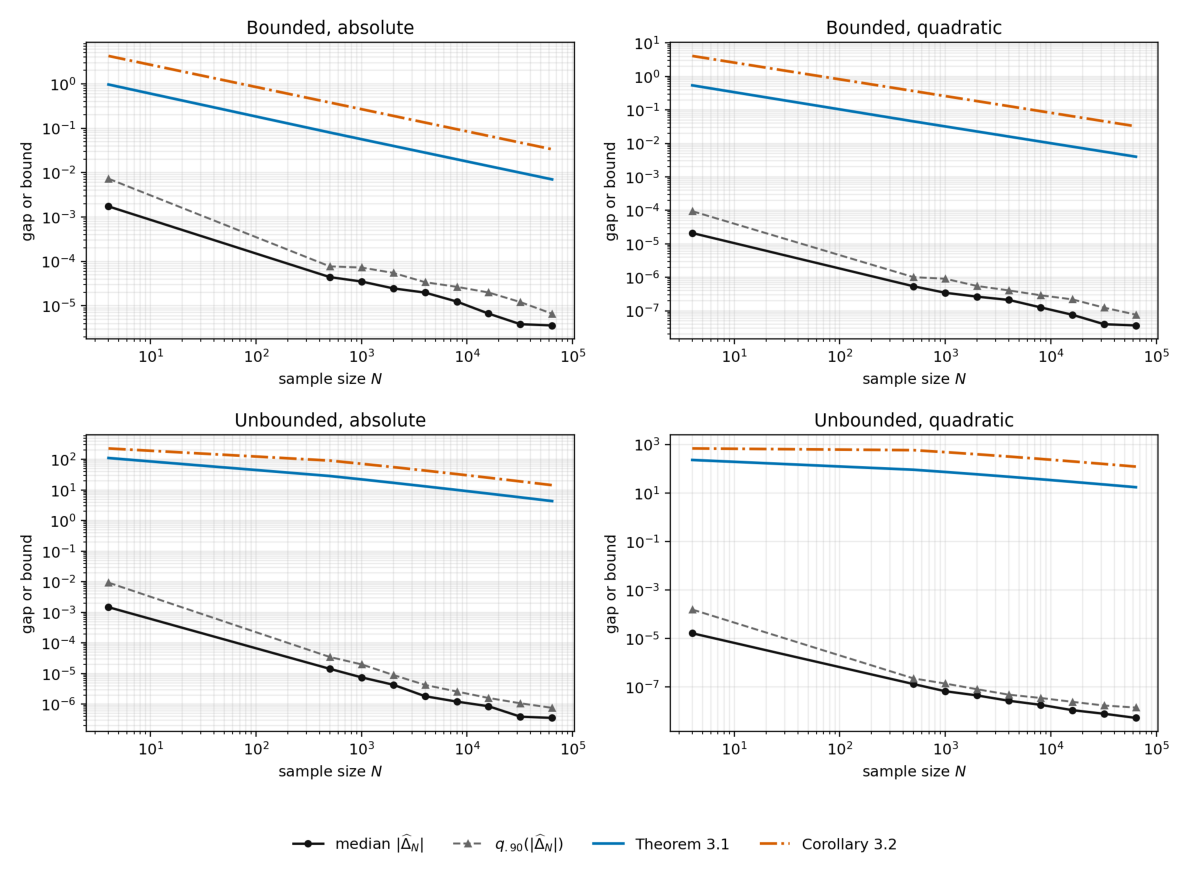

In [35]:
plot_results = results.assign(
    OT=results["theorem_3_1"],
    OC=results["corollary_3_2"],
)
make_paper_plots(OUTPUT_DIR, plot_results, gap_slopes)

gap_figure = plt.imread(OUTPUT_DIR / "uniform_gap_vs_bounds.png")
fig, ax = plt.subplots(figsize=(12, 9))
ax.imshow(gap_figure)
ax.axis("off")
plt.tight_layout()
plt.show()


## 32. Plot the slopes

Show the fitted slopes of the raw median and $q_{.90}$ gaps with their 95% bootstrap intervals. The line at $-1/2$ is only a reference. The paper's rates are upper bounds. They are not exact rates.


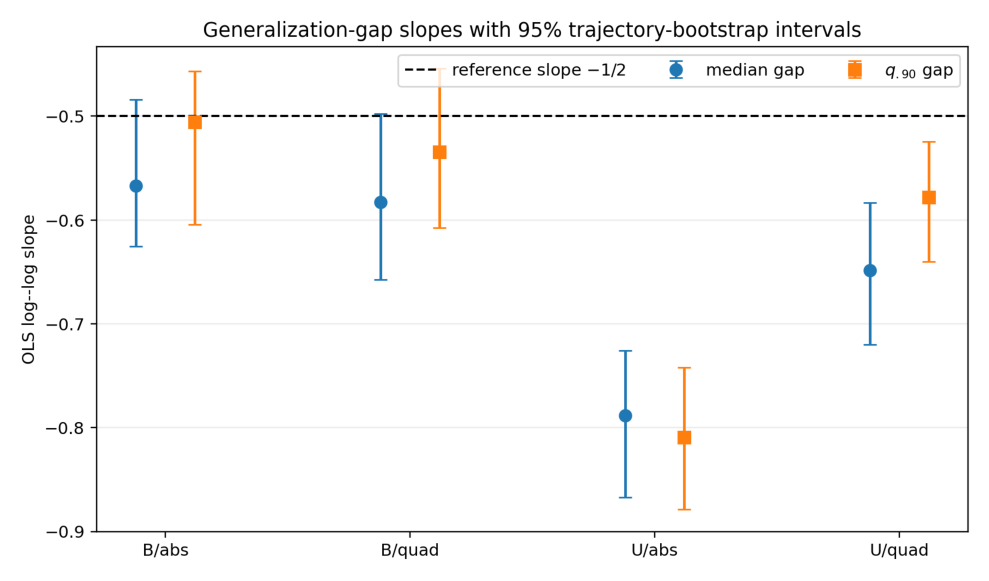

In [36]:
slope_figure = plt.imread(OUTPUT_DIR / "uniform_gap_slopes.png")
fig, ax = plt.subplots(figsize=(10, 6))
ax.imshow(slope_figure)
ax.axis("off")
plt.tight_layout()
plt.show()


## 33. Final checks

The last cell checks the system dimensions, stability, KL value, posterior weights, number of gap rows, bounds, slopes, and all eight strict $N_1$ comparisons. It also saves the settings and key numerical values to a JSON file and lists the output files.


In [37]:
assert np.allclose(system.A_theta(theta_true), A_g)
assert np.allclose(prior_corner_radii, 0.25)
assert np.isclose(uniform_box_kl(settings), 2.0 * np.log(8.0))
assert len(posterior_nodes) == settings.posterior_quadrature_order**2
assert np.isclose(posterior_weights.sum(), 1.0)
assert len(gap_trials) == 2 * 2 * len(settings.sample_sizes) * settings.monte_carlo_trials
assert len(paper_table) == 8
assert np.isfinite(submitted_bounds[["theorem_3_1", "corollary_3_2"]]).all().all()
assert np.isfinite(gap_slopes["slope"]).all()
assert bool(n1_table["strict_inequality_verified"].all())
assert bool((n1_table["bound_at_N_1"] < n1_table["gap_at_N_g"]).all())

check = {
    "settings": asdict(settings),
    "theta_true": theta_true.tolist(),
    "A_g": A_g.tolist(),
    "D_1": D_1.tolist(),
    "D_2": D_2.tolist(),
    "B": B.tolist(),
    "C": C.tolist(),
    "maximum_prior_corner_spectral_radius": float(prior_corner_radii.max()),
    "KL_exact": float(uniform_box_kl(settings)),
    "posterior_quadrature_nodes": int(len(posterior_nodes)),
    "bound_evaluation_uses_Monte_Carlo": False,
    "quadratic_true_error_is_analytic": True,
    "absolute_true_error_uses_independent_stationary_Sobol_reference": True,
    "main_independent_data_realizations": int(settings.monte_carlo_trials),
    "N_g_4_independent_data_realizations": int(settings.early_gap_trials),
    "bootstrap_repetitions": 4000,
    "all_N1_strict_inequalities_verified": True,
}
(OUTPUT_DIR / "validation_check.json").write_text(
    json.dumps(check, indent=2), encoding="utf-8"
)

print("All checks passed. Generated files:")
for path in sorted(OUTPUT_DIR.iterdir()):
    if path.is_file():
        print(" -", path.name)


All checks passed. Generated files:
 - early_N4_gap_summary.csv
 - early_N4_gap_trials.csv
 - gap_summary.csv
 - gap_trials.csv
 - submitted_bounds.csv
 - uniform_N1000_bound_constants.csv
 - uniform_N1_q90.csv
 - uniform_bounded_absolute_gap_vs_bounds.png
 - uniform_bounded_quadratic_gap_vs_bounds.png
 - uniform_constants.csv
 - uniform_gap_slope_bootstrap.csv
 - uniform_gap_slopes.csv
 - uniform_gap_slopes.pdf
 - uniform_gap_slopes.png
 - uniform_gap_vs_bounds.pdf
 - uniform_gap_vs_bounds.png
 - uniform_results_all_N.csv
 - uniform_paper_table.csv
 - uniform_unbounded_absolute_gap_vs_bounds.png
 - uniform_unbounded_quadratic_gap_vs_bounds.png
 - validation_check.json
